## Exploratory Data Analysis

In [73]:
from pathlib import Path
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / 'data').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

### Data Loading

In [75]:
DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'case_cc_fraud.csv'

if not DATA_PATH.is_file():
    raise FileNotFoundError(f'Dataset does not exist: {DATA_PATH}')

df = pd.read_csv(
    DATA_PATH,
    dtype={
        'cc_num': 'string', 'zip': 'string',
        'merchant': 'category', 'category': 'category',
        'gender': 'category', 'state': 'category',
    },
)

print(f'Loaded {len(df):,} transactions.')

Loaded 1,852,394 transactions.


### Dataset Overview

In [76]:
print(f'Number of rows: {df.shape[0]:,}')
print(f'Number of columns: {df.shape[1]}')

pd.DataFrame({'column': df.columns, 'data type': df.dtypes.astype(str).values})

Number of rows: 1,852,394
Number of columns: 22


,column,data type
0,trans_date_trans_time,object
1,cc_num,string
2,merchant,category
3,category,category
4,amt,float64
5,first,object
6,last,object
7,gender,category
8,street,object
9,city,object


### Missing Values

In [77]:
missing = df.isna().sum()
pd.DataFrame({
    'missing values': missing,
    'percentage': missing / len(df) * 100,
})

,missing values,percentage
trans_date_trans_time,0,0.0
cc_num,0,0.0
merchant,0,0.0
category,0,0.0
amt,0,0.0
first,0,0.0
last,0,0.0
gender,0,0.0
street,0,0.0
city,0,0.0


### Duplicate Records

In [79]:
print(f'Duplicate rows: {df.duplicated().sum():,}')

df = df.drop_duplicates().copy()
conflicting_trans_num = df['trans_num'].duplicated(keep=False) & df['trans_num'].notna()

print(f'Rows with matching transaction numbers after removing exact duplicates: {conflicting_trans_num.sum():,}')
print(f'Matching transaction numbers to review: {df.loc[conflicting_trans_num, "trans_num"].nunique():,}')
print(f'Missing transaction number: {df["trans_num"].isna().sum():,}')
print(f'Rows after removing exact duplicates: {len(df):,}')

Duplicate rows: 0
Rows with matching transaction numbers after removing exact duplicates: 0
Matching transaction numbers to review: 0
Missing transaction number: 0
Rows after removing exact duplicates: 1,852,394


### Dates and Chronological Order

In [82]:
df['trans_date_trans_time'] = pd.to_datetime(df['trans_date_trans_time'], errors='coerce')
time = df['trans_date_trans_time']
invalid_dates = int(time.isna().sum())

print('From:', time.min())
print('To:', time.max())
print('Missing or invalid dates:', invalid_dates)

if invalid_dates:
    print('Chronological order cannot be reliably checked.')
else:
    print('Chronologically sorted:', time.is_monotonic_increasing)

From: 2019-01-01 00:00:18
To: 2020-12-31 23:59:34
Missing or invalid dates: 0
Chronologically sorted: False


#### Data Validation

In [88]:
dob = pd.to_datetime(df['dob'], errors='coerce')
age = (df['trans_date_trans_time'] - dob).dt.days / 365.25
unix_date = pd.to_datetime(df['unix_time'], unit='s', utc=True, errors='coerce').dt.tz_localize(None)
valid_coordinates = (
    df['lat'].between(-90, 90) & df['long'].between(-180, 180)
    & df['merch_lat'].between(-90, 90) & df['merch_long'].between(-180, 180)
)

checks = pd.Series({
    'Zero or negative amount': ((df['amt'] <= 0) & df['amt'].notna()).sum(),
    'Missing amount': df['amt'].isna().sum(),
    'Invalid or missing date of birth': dob.isna().sum(),
    'Age outside 0–120 years': (age.notna() & ~age.between(0, 120)).sum(),
    'Missing or invalid coordinates': (~valid_coordinates).sum(),
    'Invalid or missing fraud label': (~df['is_fraud'].isin([0, 1])).sum(),
    'Invalid or missing unix_time': unix_date.isna().sum(),
})

display(checks.to_frame('count'))

,count
Zero or negative amount,0
Missing amount,0
Invalid or missing date of birth,0
Age outside 0–120 years,0
Missing or invalid coordinates,0
Invalid or missing fraud label,0
Invalid or missing unix_time,0


### Fraud vs. Non-Fraud

,count,percentage
is_fraud,,
0,1842743,99.478999
1,9651,0.521001


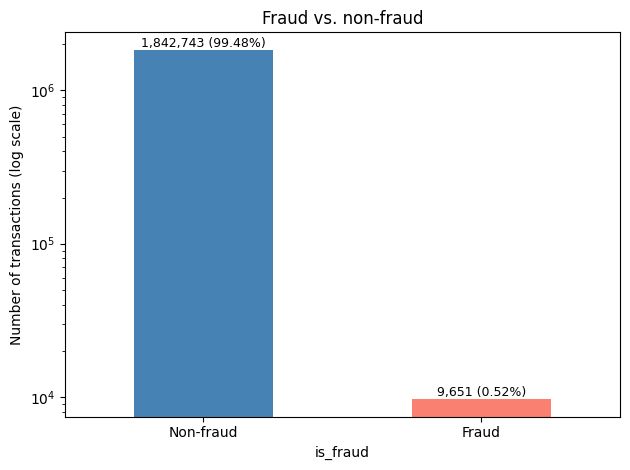

In [89]:
target = df['is_fraud'].value_counts().reindex([0, 1], fill_value=0)
target_table = pd.DataFrame({'count': target, 'percentage': target / target.sum() * 100})

display(target_table)

ax = target.rename(index={0: 'Non-fraud', 1: 'Fraud'}).plot.bar(color=['steelblue', 'salmon'])

for bar, count in zip(ax.patches, target):
    if count:
        ax.annotate(f'{count:,} ({count / target.sum() * 100:.2f}%)',
                    (bar.get_x() + bar.get_width() / 2, count),
                    ha='center', va='bottom', fontsize=9)
        
plt.yscale('log')
plt.ylabel('Number of transactions (log scale)')
plt.title('Fraud vs. non-fraud')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Trends Over Time

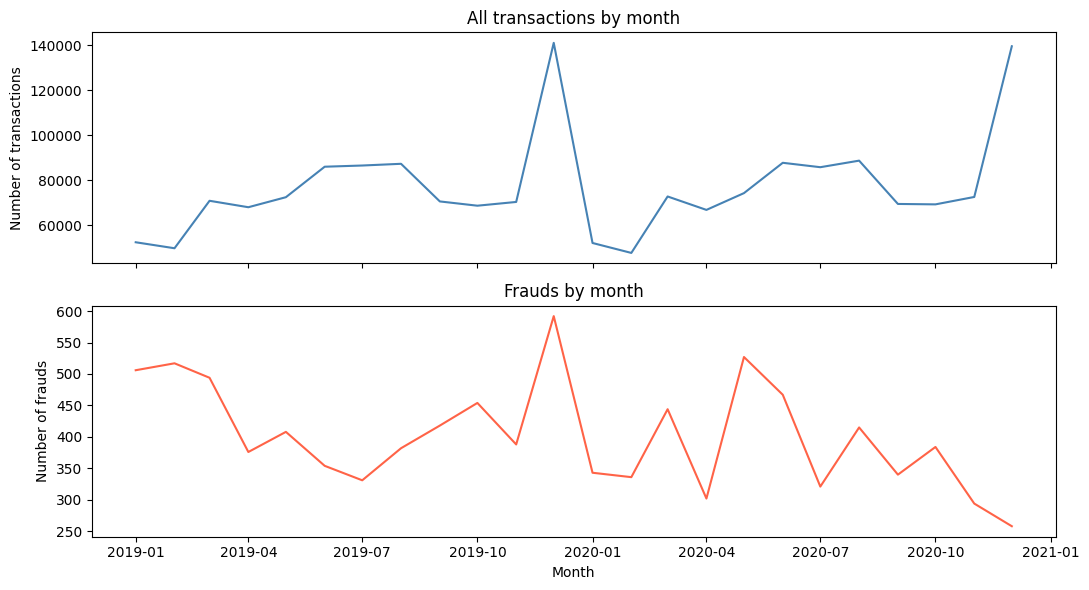

In [91]:
monthly = df.set_index('trans_date_trans_time').resample('MS')['is_fraud'].agg(['count', 'sum', 'mean'])
monthly.columns = ['transactions', 'frauds', 'fraud_rate']

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(monthly.index, monthly['transactions'], color='steelblue')
axes[0].set_title('All transactions by month')
axes[0].set_ylabel('Number of transactions')
axes[1].plot(monthly.index, monthly['frauds'], color='tomato')
axes[1].set_title('Frauds by month')
axes[1].set_ylabel('Number of frauds')
axes[1].set_xlabel('Month')
plt.tight_layout()
plt.show()


### Cards and Merchants

In [93]:
cards = df['cc_num'].nunique()

print(f'Unique cards: {cards:,}')
print(f'Unique merchants: {df["merchant"].nunique():,}')
print(f'Average transactions per card: {len(df) / cards:,.1f}')

Unique cards: 999
Unique merchants: 693
Average transactions per card: 1,854.2


#### Fraud by Card

In [95]:
card_frauds = df.groupby('cc_num', observed=True)['is_fraud'].sum()

print('Cards with at least one fraud:', int((card_frauds > 0).sum()))
print('Cards without fraud:', int((card_frauds == 0).sum()))
print('Missing card numbers:', int(df['cc_num'].isna().sum()))

card_frauds[card_frauds > 0].describe(percentiles=[0.5, 0.9, 0.99]).to_frame('frauds per card')

Cards with at least one fraud: 976
Cards without fraud: 23
Missing card numbers: 0


,frauds per card
count,976.000000
mean,9.888320
std,2.983859
min,2.000000
50%,10.000000
90%,14.000000
99%,16.000000
max,19.000000


### Transactions by Hour

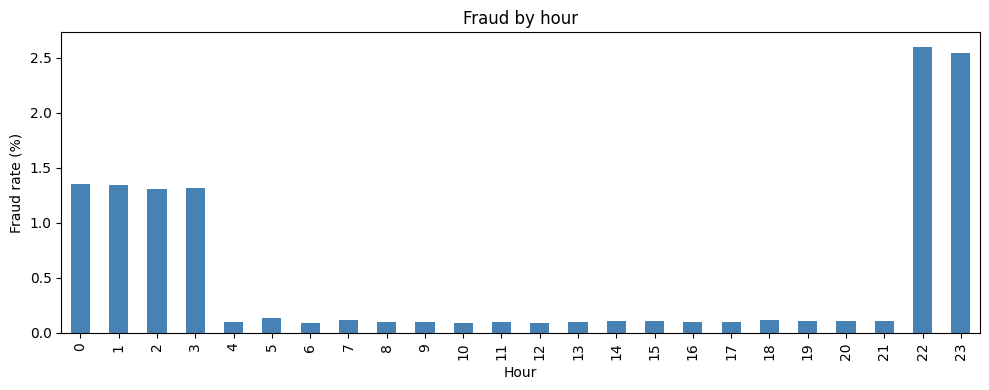

,transactions,frauds,fraud rate
hour,,,
0,60655,823,0.013569
1,61330,827,0.013484
2,60796,793,0.013044
3,60968,803,0.013171
4,59938,61,0.001018
5,60088,80,0.001331
6,60406,54,0.000894
7,60301,72,0.001194
8,60498,59,0.000975


In [97]:
df['hour'] = df['trans_date_trans_time'].dt.hour
hourly = df.groupby('hour')['is_fraud'].agg(['count', 'sum', 'mean'])

(hourly['mean'] * 100).plot.bar(color='steelblue', figsize=(10, 4))

plt.xlabel('Hour')
plt.ylabel('Fraud rate (%)')
plt.title('Fraud by hour')
plt.tight_layout()
plt.show()

hourly.rename(columns={'count': 'transactions', 'sum': 'frauds', 'mean': 'fraud rate'})

### Transactions by Day of Week

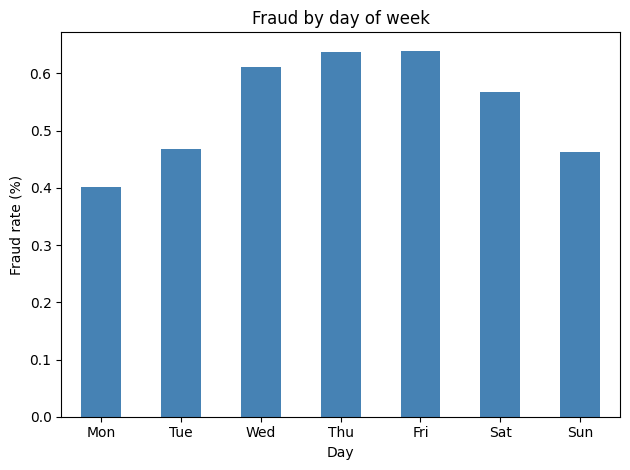

,transactions,frauds,fraud rate
Mon,369418,1484,0.004017
Tue,270340,1266,0.004683
Wed,183913,1125,0.006117
Thu,206741,1317,0.006370
Fri,215078,1376,0.006398
Sat,263227,1493,0.005672
Sun,343677,1590,0.004626


In [98]:
df['day_of_week'] = df['trans_date_trans_time'].dt.dayofweek
daily = df.groupby('day_of_week')['is_fraud'].agg(['count', 'sum', 'mean']).reindex(range(7))

daily.index = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
(daily['mean'] * 100).plot.bar(color='steelblue')

plt.xlabel('Day')
plt.ylabel('Fraud rate (%)')
plt.title('Fraud by day of week')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

daily.rename(columns={'count': 'transactions', 'sum': 'frauds', 'mean': 'fraud rate'})

### Transaction Amount

,count,mean,std,min,50%,90%,99%,max
is_fraud,,,,,,,,
0,1842743.0,67.651278,153.548108,1.00,47.24,134.17,484.91,28948.90
1,9651.0,530.661412,391.028873,1.06,390.00,1024.61,1175.85,1376.04


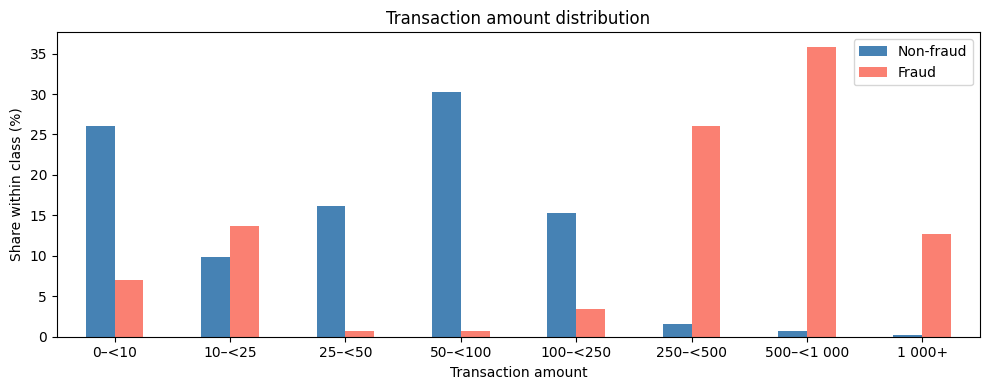

Transaction counts by range:


is_fraud,Non-fraud,Fraud
0–<10,479187,672
10–<25,181340,1326
25–<50,298501,71
50–<100,556286,63
100–<250,280698,327
250–<500,29706,2508
500–<1 000,12731,3458
1 000+,4294,1226


In [101]:
display(df.groupby('is_fraud')['amt'].describe(percentiles=[0.5, 0.9, 0.99]))

amount_groups = pd.cut(df['amt'], bins=[0, 10, 25, 50, 100, 250, 500, 1000, np.inf],
                       labels=['0–<10', '10–<25', '25–<50', '50–<100', '100–<250', '250–<500', '500–<1 000', '1 000+'],
                       right=False)
amount_counts = pd.crosstab(amount_groups, df['is_fraud']).reindex(index=amount_groups.cat.categories, columns=[0, 1], fill_value=0)

amount_percent = amount_counts.div(amount_counts.sum(axis=0).replace(0, np.nan), axis=1) * 100
amount_percent.columns = ['Non-fraud', 'Fraud']
amount_percent.plot.bar(figsize=(10, 4), color=['steelblue', 'salmon'], rot=0)

plt.xlabel('Transaction amount')
plt.ylabel('Share within class (%)')
plt.title('Transaction amount distribution')
plt.legend(title='')
plt.tight_layout()
plt.show()

print('Transaction counts by range:')

amount_counts.rename(columns={0: 'Non-fraud', 1: 'Fraud'})

### Distance Between Customer and Merchant

In [103]:
def haversine_km(lat1, lon1, lat2, lon2):
    earth_radius_km = 6371.0088

    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    delta_lat = lat2 - lat1
    delta_lon = lon2 - lon1
    
    a = np.sin(delta_lat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(delta_lon / 2) ** 2

    return 2 * earth_radius_km * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

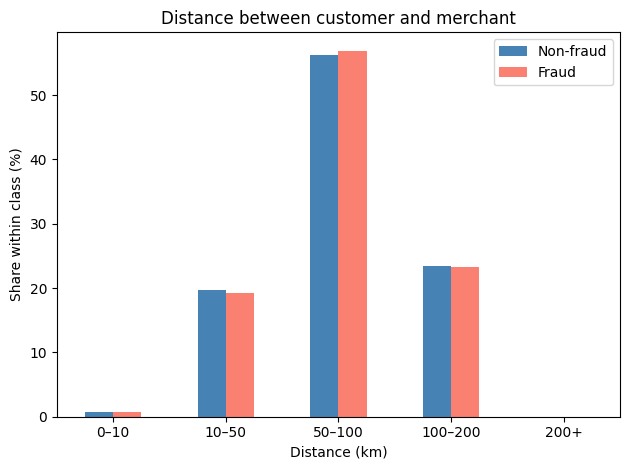

Transactions without a valid distance: 0


is_fraud,Non-fraud,Fraud
0–10,14913,68
10–50,362088,1850
50–100,1035302,5491
100–200,430440,2242
200+,0,0


In [104]:
df['distance_km'] = haversine_km(
    df['lat'].to_numpy(), df['long'].to_numpy(),
    df['merch_lat'].to_numpy(), df['merch_long'].to_numpy(),
)

df.loc[~valid_coordinates, 'distance_km'] = np.nan

distance_group = pd.cut(df['distance_km'], bins=[0, 10, 50, 100, 200, np.inf],
                        labels=['0–10', '10–50', '50–100', '100–200', '200+'],
                        right=False)

distance_counts = pd.crosstab(distance_group, df['is_fraud']).reindex(index=distance_group.cat.categories, columns=[0, 1], fill_value=0)
distance_percent = distance_counts.div(distance_counts.sum(axis=0).replace(0, np.nan), axis=1) * 100
distance_percent.columns = ['Non-fraud', 'Fraud']
distance_percent.plot.bar(color=['steelblue', 'salmon'], rot=0)

plt.xlabel('Distance (km)')
plt.ylabel('Share within class (%)')
plt.title('Distance between customer and merchant')
plt.legend(title='')
plt.tight_layout()
plt.show()

print('Transactions without a valid distance:', int(df['distance_km'].isna().sum()))
distance_counts.rename(columns={0: 'Non-fraud', 1: 'Fraud'})

#### Fraud by Distance

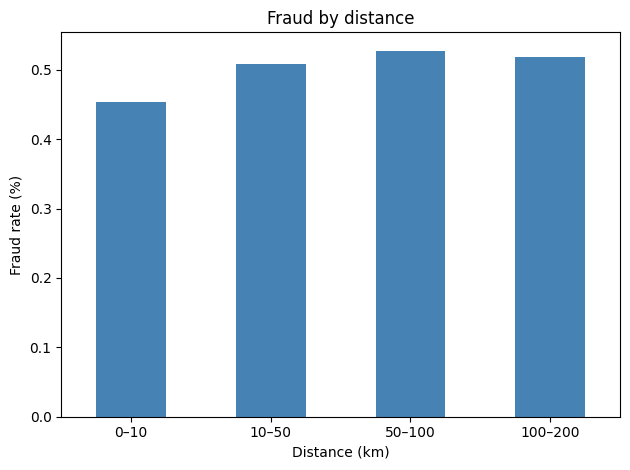

,transactions,frauds,fraud rate
distance_km,,,
0–10,14981,68,0.004539
10–50,363938,1850,0.005083
50–100,1040793,5491,0.005276
100–200,432682,2242,0.005182


In [ ]:
distance_group = pd.cut(df['distance_km'], bins=[0, 10, 50, 100, 200, np.inf],
                        labels=['0–10', '10–50', '50–100', '100–200', '200+'],
                        right=False)

distance_stats = df.groupby(distance_group, observed=True)['is_fraud'].agg(['count', 'sum', 'mean'])
(distance_stats['mean'] * 100).plot.bar(color='steelblue')

plt.xlabel('Distance (km)')
plt.ylabel('Fraud rate (%)')
plt.title('Fraud by distance')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

distance_stats.rename(columns={'count': 'transactions', 'sum': 'frauds', 'mean': 'fraud rate'})

### Customer Age

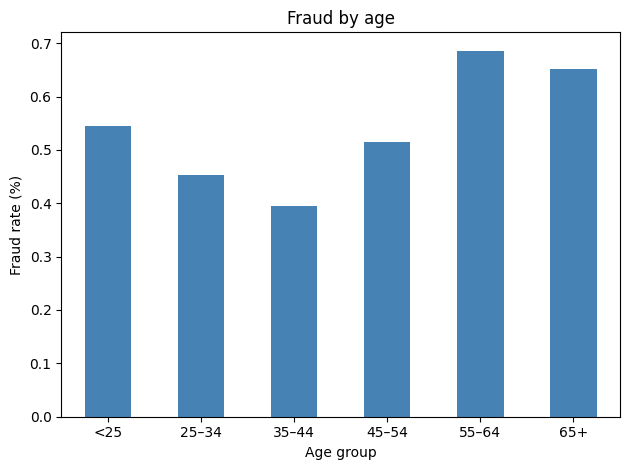

In [106]:
dob = pd.to_datetime(df['dob'], errors='coerce')
df['age'] = (df['trans_date_trans_time'] - dob).dt.days / 365.25

df['age_group'] = pd.cut(
    df['age'], bins=[0, 25, 35, 45, 55, 65, np.inf],
    labels=['<25', '25–34', '35–44', '45–54', '55–64', '65+'], right=False,
)

age_stats = df.groupby('age_group', observed=True)['is_fraud'].agg(['mean', 'count', 'sum'])
(age_stats['mean'] * 100).plot.bar(color='steelblue')

plt.xlabel('Age group')
plt.ylabel('Fraud rate (%)')
plt.title('Fraud by age')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Merchant Category and Fraud Amount

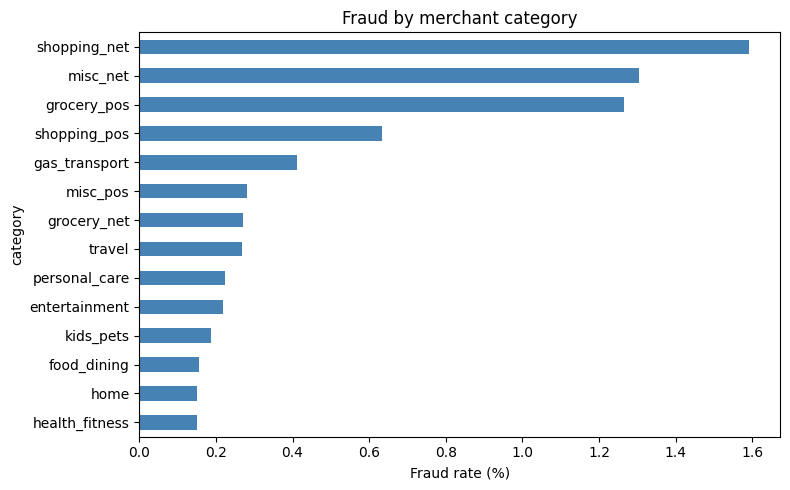

,mean,count,sum
category,,,
shopping_net,0.015927,139322,2219
misc_net,0.013039,90654,1182
grocery_pos,0.012645,176191,2228
shopping_pos,0.006344,166463,1056
gas_transport,0.004106,188029,772
misc_pos,0.002819,114229,322
grocery_net,0.002697,64878,175
travel,0.002692,57956,156
personal_care,0.002229,130085,290


In [107]:
category_stats = df.groupby('category', observed=True)['is_fraud'].agg(['mean', 'count', 'sum'])

(category_stats['mean'].sort_values() * 100).plot.barh(color='steelblue', figsize=(8, 5))

plt.xlabel('Fraud rate (%)')
plt.title('Fraud by merchant category')
plt.tight_layout()
plt.show()

category_stats.sort_values('mean', ascending=False)

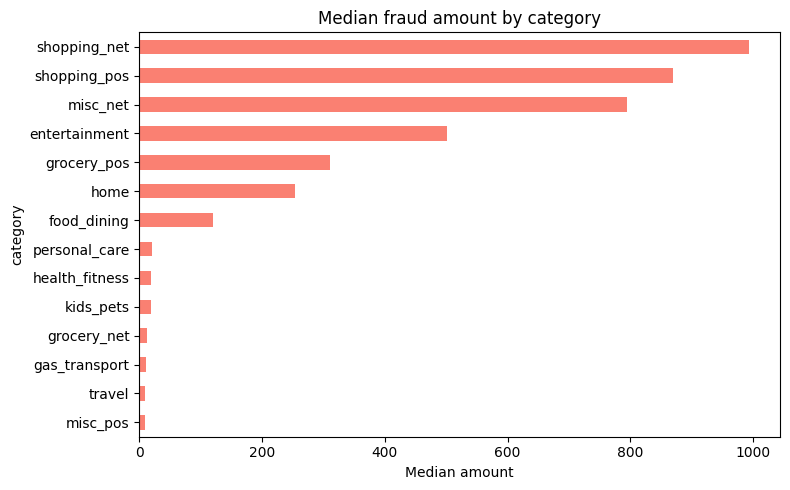

,count,median,sum
category,,,
grocery_pos,2228,310.235,695664.62
shopping_net,2219,994.150,2214847.64
misc_net,1182,794.215,944009.71
shopping_pos,1056,869.915,928132.34
gas_transport,772,10.640,9442.53
misc_pos,322,9.100,68494.84
kids_pets,304,19.645,5619.53
entertainment,292,500.835,147399.96
personal_care,290,20.970,7571.96


In [108]:
fraud_amount = df.loc[df['is_fraud'] == 1].groupby('category', observed=True)['amt'].median()

fraud_amount.sort_values().plot.barh(color='salmon', figsize=(8, 5))

plt.xlabel('Median amount')
plt.title('Median fraud amount by category')
plt.tight_layout()
plt.show()

fraud_amount_counts = df.loc[df['is_fraud'] == 1].groupby('category', observed=True)['amt'].agg(['count', 'median', 'sum'])
fraud_amount_counts.sort_values('count', ascending=False)

### Customer City Size

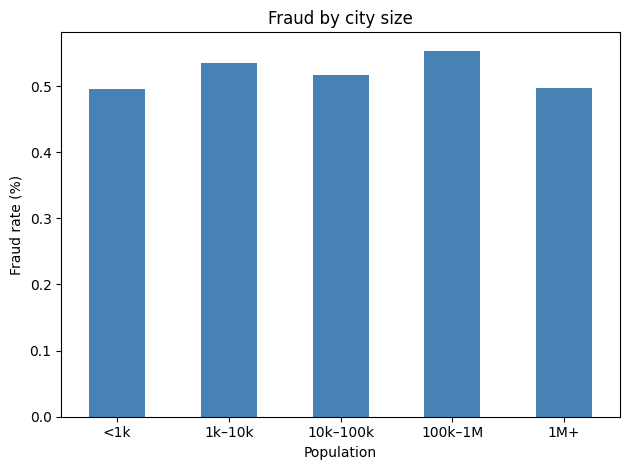

In [111]:
df['city_size'] = pd.cut(
    df['city_pop'], bins=[0, 1_000, 10_000, 100_000, 1_000_000, np.inf],
    labels=['<1k', '1k–10k', '10k–100k', '100k–1M', '1M+'], right=False,
)

city_stats = df.groupby('city_size', observed=True)['is_fraud'].agg(['mean', 'count', 'sum'])

(city_stats['mean'] * 100).plot.bar(color='steelblue')

plt.xlabel('Population')
plt.ylabel('Fraud rate (%)')
plt.title('Fraud by city size')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Correlation Matrix

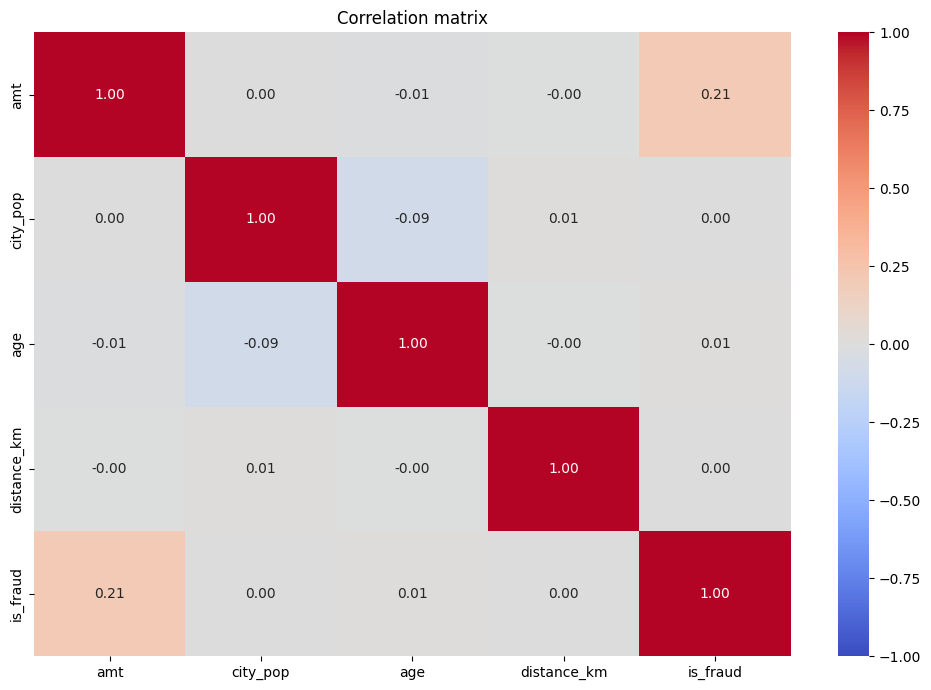

In [112]:
correlation_data = df[['amt', 'city_pop', 'age', 'distance_km', 'is_fraud']].reset_index(drop=True).copy()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation_data.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation matrix')
plt.tight_layout()
plt.show()